# Mini Project: Random Forest Regression
## Predicting Medical Insurance Charges

Group members: Shaden, Norah, Aljoharh, Sulaiman.

# 1. Introduction

In this project we use **Random Forest Regression** to predict a person's yearly **medical insurance charges**.

**Dataset:** Medical Cost Personal Dataset (Kaggle), 1,338 people.

**Goal:** find which factors affect insurance cost the most and build a model that predicts it accurately.

# 2. Algorithm Explanation

#2. 1- What is the algorithm?

Random Forest Regression is a machine learning algorithm that uses multiple decision trees to predict continuous numerical values, such as insurance charges. It combines their predictions to produce a more accurate and reliable result.

#2. 2- How does the algorithm work?

Random Forest builds multiple decision trees using random samples of the data and random subsets of features. Each tree predicts a value, and the final prediction is the average of all trees’ predictions.

#2. 3- When should this algorithm be used?

- When the relationship between the features and the target is not linear.
- When features affect each other. In our data, for example, BMI matters a lot for smokers but only a little for non-smokers.
- When the data has a mix of numbers and categories, like age and bmi alongside smoker and region.
- When we want good accuracy without much preprocessing, since it doesn’t need feature scaling.

#2. 4- Advantages and Limitations
**Advantages**
1. High accuracy: usually better than linear regression on complex data.
2. Less overfitting than a single decision tree, because of averaging.
3. Robust to outliers, which suits the insurance charges with their very high values.
4. No feature scaling needed: trees split on thresholds, so it doesn’t matter whether age and charges are on different scales.


**Limitations**
1. Hard to interpret: there’s no single simple equation like in linear regression.
2. Slower and uses more memory, since it trains and stores many trees.
3. Still needs categorical features encoded (for example, smoker yes/no → 1/0) in scikit-learn.
4. Needs tuning for best results, for example number of trees, max_depth and min_samples_leaf.

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Dataset Exploration (EDA)

In [33]:
df = pd.read_csv("https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
print("Shape:", df.shape)
print()
df.info()

Shape: (1338, 7)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
print(df.describe())

               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16639.912515
max      64.000000    53.130000     5.000000  63770.428010


In [8]:
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


* **Target:** `charges`
* **Features:** `age`, `sex`, `bmi`, `children`, `smoker`, `region`
* Numerical features: age, bmi, children
* Categorical features: sex, smoker, region
* There are **no missing values** and **1 duplicate row**.

### Histogram of charges

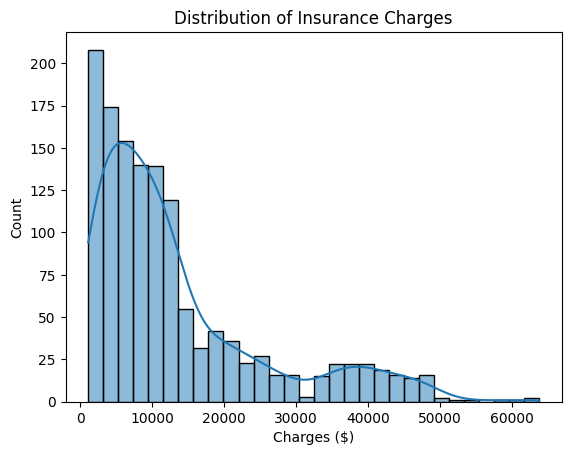

Mean: 13270.42
Median: 9382.03


In [9]:
sns.histplot(df["charges"], kde=True)
plt.title("Distribution of Insurance Charges")
plt.xlabel("Charges ($)")
plt.show()

print("Mean:", round(df["charges"].mean(), 2))
print("Median:", round(df["charges"].median(), 2))

The charges are **right-skewed**: most people pay less than about \$17,000, but a smaller group pays much more (up to about \$63,000). The mean is higher than the median because of these high values.

### Age vs Charges

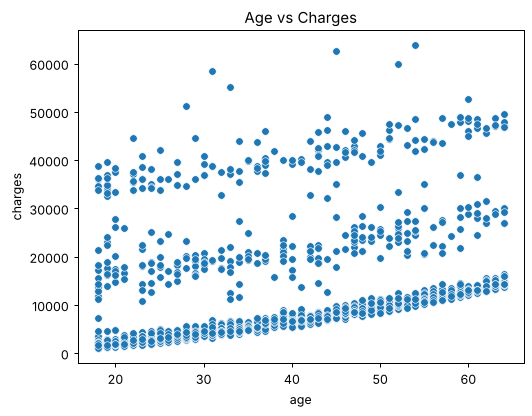

In [ ]:
sns.scatterplot(x="age", y="charges", data=df)
plt.title("Age vs Charges")
plt.show()

Charges **increase with age**. The points form about three separate bands, which suggests another factor (smoking) splits people into groups that pay different amounts.

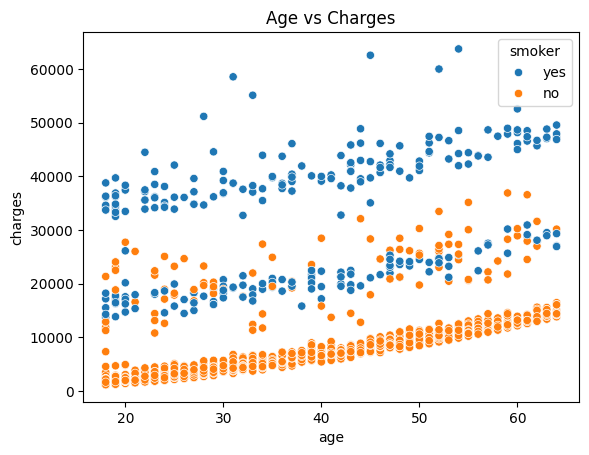

In [10]:
#colord by smoker
sns.scatterplot(x="age", y="charges",  hue="smoker", data=df)
plt.title("Age vs Charges")
plt.show()

### BMI vs Charges (colored by smoker)

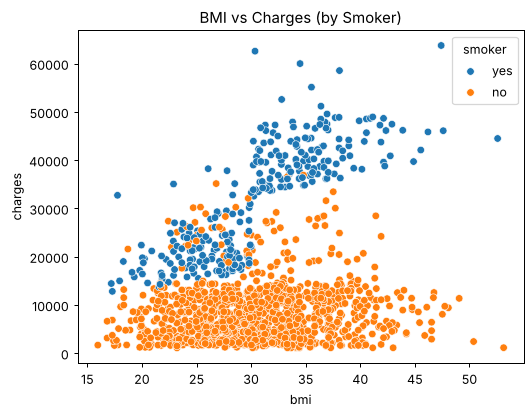

In [ ]:
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=df)
plt.title("BMI vs Charges (by Smoker)")
plt.show()

For **non-smokers**, BMI has almost no effect on charges. For **smokers**, charges jump sharply when BMI is above 30. So smoking and BMI **together** have a big effect.

### Charges by Smoker

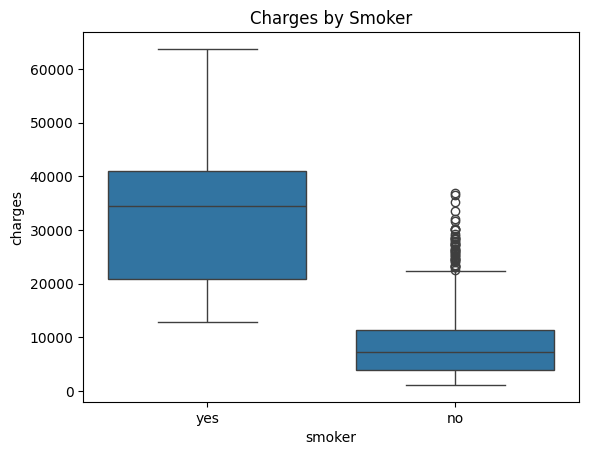

smoker
no      8434.27
yes    32050.23
Name: charges, dtype: float64


In [11]:
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Charges by Smoker")
plt.show()

print(df.groupby("smoker")["charges"].mean().round(2))

Smokers pay about **4 times more** than non-smokers on average. Smoking is the most important factor in the dataset.

**Outliers:**
* The **non-smoker** group has many outliers above the upper whisker (about \$22,400), with charges up to about \$37,000. These are non-smokers who pay much more than usual, possibly because of older age, high BMI or other health conditions not included in the dataset.
* The **smoker** group has **no outliers**, but its box is much taller, so smokers' charges are much more spread out (from about \$13,000 to over \$60,000).
* These outliers are **real values, not errors**, so we keep them in the data. Random Forest is not strongly affected by outliers, so they don't need to be removed.

### Correlation Heatmap

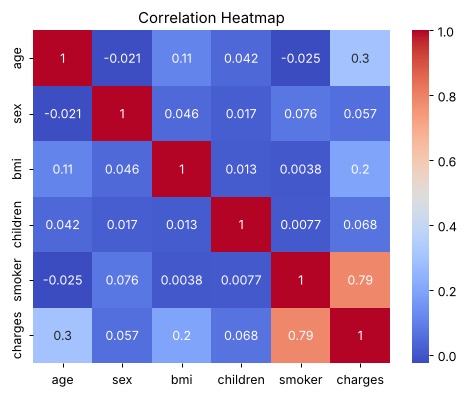

In [ ]:
df_corr = df.copy()
df_corr["sex"] = df_corr["sex"].map({"male": 1, "female": 0})
df_corr["smoker"] = df_corr["smoker"].map({"yes": 1, "no": 0})

sns.heatmap(df_corr.drop(columns="region").corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

* **smoker** has the strongest correlation with charges (0.79)
* **age** (0.30) and **bmi** (0.20) have a moderate effect
* **sex** and **children** have very weak correlation with charges

# 4. Data Preprocessing

* **Missing values:** none, so nothing to fill.
* **Duplicates:** remove the 1 duplicate row.
* **Encoding:** convert categorical columns to numbers.
* **Scaling:** **not needed** for Random Forest, because trees split on thresholds and are not affected by the scale of the features.

In [34]:
#remove duplicats
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 7)


In [35]:
# Encode categorical variables
df = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
df.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [36]:
X = df.drop(columns="charges")
y = df["charges"]

print("Features:", X.columns.tolist())

Features: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [37]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1069, 8)
Testing set: (268, 8)


# 5. Model Training

We train a Random Forest with 100 trees.

In [38]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# 6. Model Evaluation

In [41]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 4))

MAE : 2637.99
MSE : 22113000.54
RMSE: 4702.45
R²  : 0.8797


**Interpretation:**

* **MAE ≈ \$2,637:** on average, the model's prediction is about \$2,600 away from the real charges.
* **RMSE ≈ \$4,702:** higher than the MAE, which means there are some large errors (mainly for very expensive cases).
* **R² ≈ 0.88:** the model explains about **88%** of the variation in insurance charges, which is a good result.

### Bonus: Comparison with Linear Regression

In [42]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mean_absolute_error(y_test, lr_pred), mae],
    "RMSE": [np.sqrt(mean_squared_error(y_test, lr_pred)), rmse],
    "R²": [r2_score(y_test, lr_pred), r2]
}).round(3)

print(comparison)

               Model       MAE      RMSE     R²
0  Linear Regression  4177.046  5956.343  0.807
1      Random Forest  2637.995  4702.446  0.880


Random Forest performs better than Linear Regression on every metric: lower errors and a higher R² (0.88 vs 0.81). This is because Random Forest can learn the **non-linear** relationship between smoking, BMI and charges, while Linear Regression can only fit a straight-line relationship.

### Bonus: Hyperparameter Tuning

The first model used the default settings, where each tree grows as deep as it can. That can make the trees memorize the training data (overfitting).
We use **GridSearchCV** to try different combinations of settings and pick the best one using 5-fold cross-validation:

* `n_estimators`: number of trees in the forest
* `max_depth`: how deep each tree can grow
* `min_samples_leaf`: the minimum number of rows in each final leaf

In [43]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 4, 6, 8],
    "min_samples_leaf": [1, 5, 10]
}

grid = GridSearchCV(RandomForestRegressor(random_state=42),
                    param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation R²:", round(grid.best_score_, 4))

Best parameters: {'max_depth': 4, 'min_samples_leaf': 5, 'n_estimators': 200}
Best cross-validation R²: 0.8439


In [44]:
best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest (default)", "Random Forest (tuned)"],
    "MAE": [mean_absolute_error(y_test, lr_pred), mae, mean_absolute_error(y_test, best_pred)],
    "RMSE": [np.sqrt(mean_squared_error(y_test, lr_pred)), rmse, np.sqrt(mean_squared_error(y_test, best_pred))],
    "R²": [r2_score(y_test, lr_pred), r2, r2_score(y_test, best_pred)]
}).round(3)

results

,Model,MAE,RMSE,R²
0,Linear Regression,4177.046,5956.343,0.807
1,Random Forest (default),2637.995,4702.446,0.880
2,Random Forest (tuned),2454.475,4230.284,0.903


**Results:**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Linear Regression | 4,177 | 5,956 | 0.807 |
| Random Forest (default) | 2,633 | 4,698 | 0.880 |
| **Random Forest (tuned)** | **2,454** | **4,230** | **0.903** |

The best settings were **200 trees, max_depth = 4 and min_samples_leaf = 5**.
After tuning, R² improved from **0.88 to 0.90** and RMSE dropped by about **470**.
Limiting the depth of the trees and requiring at least 5 rows per leaf stopped the trees from memorizing the training data (less overfitting), so the model predicts new data better.
The tuned Random Forest is the best model overall.

# 7. Conclusion

* We used **Random Forest Regression** to predict medical insurance charges.
* The EDA showed that **smoking** is the strongest factor: smokers pay about 4 times more than non-smokers.
* Smoking and BMI **together** have a big effect: smokers with BMI above 30 have the highest charges.
* Feature importance confirmed that **smoker, bmi and age** are the most important features, while sex, children and region have almost no effect.
* The default Random Forest achieved **R² = 0.88**, better than Linear Regression (**R² = 0.81**), because it captures non-linear relationships.
* **Hyperparameter tuning** (200 trees, max_depth = 4, min_samples_leaf = 5) improved the model to **R² = 0.90** and **MAE ≈ 2,454** by reducing overfitting.
* The **tuned Random Forest** is the best model, explaining about 90% of the variation in insurance charges.